### EDA

In [923]:
#import
from pathlib import Path
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
import numpy as np


In [924]:
color_palette = matplotlib.colormaps['Set2'].colors

def rgb_to_hex(r, g, b):
    return '#{:02x}{:02x}{:02x}'.format(int(r*255), int(g*255), int(b*255))

palettehex = [rgb_to_hex(*c) for c in color_palette]

In [978]:
project_root = Path().resolve()
# data_path = Path(project_root/ "data"/ "train.csv")
data_path = Path(project_root/ "data"/ "test.csv")
df = pd.read_csv(data_path)

### First glimpse

In [979]:
df.head()

,nom_du_projet,resume_du_projet,montant_engage,numero_ej,numero_operateur,opérateur,demarche,nom_region,nom_departement,code_departement,...,siret,activitePrincipale,codePostal,dateCreation,categorieEntreprise,trancheEffectifsUniteLegale,societeMissionUniteLegale,etatAdministratifEtablissement,anneeEffectifsEtablissement,economieSocialeSolidaireUniteLegale
0,Isolation thermique par l'extérieur de murs de...,Le projet porte sur des travaux d'isolation th...,35995.88,2.104329e+09,NaN,NaN,Rénovation énergétique des bâtiments publics l...,Centre-Val de Loire,Indre,36,...,2.136019e+13,84.11Z,36500.0,1983-03-01,PME,11,NaN,A,2023.0,NaN
1,Remplacement des têtes du reste du parc d'écla...,Dans le cadre de la transition écologique-éner...,2360.36,2.104327e+09,NaN,NaN,Rénovation des parcs de luminaires d’éclairage...,Nouvelle-Aquitaine,Haute-Vienne,87,...,2.187039e+13,84.11Z,87380.0,1983-03-01,PME,11,NaN,A,2023.0,N
2,Rénovation énergétique de l'école,Rénovation énergétique et extension de l’école...,137933.00,2.104325e+09,NaN,NaN,Rénovation énergétique des bâtiments publics l...,Bretagne,Ille-et-Vilaine,35,...,2.135034e+13,84.11Z,35610.0,1983-03-01,PME,03,NaN,A,2023.0,NaN
3,RENOVATION ET BAISSE ENERGETIQUE BATIMENT SCOL...,L'établissement est actuellement équipé de néo...,3912.61,2.104405e+09,NaN,NaN,Rénovation énergétique des bâtiments publics l...,Normandie,Calvados,14,...,2.414005e+13,84.11Z,14290.0,2013-07-01,PME,12,NaN,A,2023.0,NaN
4,Application covoiturage ARCHE Agglo,Le présent projet porte sur le Volet 5 “Inci...,22957.47,2.104527e+09,NaN,NaN,Développement du covoiturage,Auvergne-Rhône-Alpes,Ardèche,07,...,2.000731e+13,84.11Z,7300.0,2017-01-01,ETI,32,NaN,A,2023.0,N


In [980]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1774 entries, 0 to 1773
Data columns (total 25 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   nom_du_projet                        1774 non-null   object 
 1   resume_du_projet                     1727 non-null   object 
 2   montant_engage                       1774 non-null   float64
 3   numero_ej                            1484 non-null   float64
 4   numero_operateur                     290 non-null    object 
 5   opérateur                            290 non-null    object 
 6   demarche                             1740 non-null   object 
 7   nom_region                           1731 non-null   object 
 8   nom_departement                      1731 non-null   object 
 9   code_departement                     1731 non-null   object 
 10  siret_beneficiaire                   1731 non-null   float64
 11  raison_sociale_beneficiaire   

In [981]:
for col in df.select_dtypes('object').columns:
    df[col] = df[col].astype('category')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1774 entries, 0 to 1773
Data columns (total 25 columns):
 #   Column                               Non-Null Count  Dtype   
---  ------                               --------------  -----   
 0   nom_du_projet                        1774 non-null   category
 1   resume_du_projet                     1727 non-null   category
 2   montant_engage                       1774 non-null   float64 
 3   numero_ej                            1484 non-null   float64 
 4   numero_operateur                     290 non-null    category
 5   opérateur                            290 non-null    category
 6   demarche                             1740 non-null   category
 7   nom_region                           1731 non-null   category
 8   nom_departement                      1731 non-null   category
 9   code_departement                     1731 non-null   category
 10  siret_beneficiaire                   1731 non-null   float64 
 11  raison_sociale_be

It becomes obvious from the basic information about the dataset that most of the variables are categorical variables. Also variables `societeMissionUniteLegale` and `numero_operateur`/`operateur` require further attention.

In [982]:
df.columns

for col in df.columns:
    df.columns = df.columns.str.replace(' ', '_').str.lower()
    df.columns = df.columns.str.normalize('NFKD').str.encode('ascii', errors='ignore').str.decode('utf-8')



This step is needed to treat the `trancheeffectifsunitelegale` values according to its type. This variable represents the ordinal structure, however it contains NN value that correspond to false information.

In [983]:
df["trancheeffectifsunitelegale"].value_counts()
#df['tranche_effectif'] = df['trancheeffectifsunitelegale'].replace('NN', 'false_info')
df['is_false_info'] = (df['trancheeffectifsunitelegale'] == 'NN').astype(int)


ordinal_map = {

    'NN': 0,
    '00': 1,
    '01': 2,
    '02': 3,
    '03': 4,
    '11': 5,
    '12': 6,
    '21': 7,
    '22': 8,
    '31': 9,
    '32': 10,
    '41': 11,
    '42': 12,
    '51': 13,
    '52': 14,
    '53': 15

}

df['trancheeffectifsunitelegale'] = (
    df['trancheeffectifsunitelegale']
    .astype('string')
    .str.strip()
    .fillna('NN')
)
df['tranche_effectif_ord'] = df['trancheeffectifsunitelegale'].map(ordinal_map)


In [984]:
df['trancheeffectifsunitelegale'].value_counts(dropna=False)
df['tranche_effectif_ord'].isna().sum()
df[df['tranche_effectif_ord'].isna()][['trancheeffectifsunitelegale']].head()

,trancheeffectifsunitelegale


The following stages will research the cardinality of the categorical variables.

In [985]:
from utilites import clean_text

categorical_cols = df.select_dtypes('category').columns

for col in df[categorical_cols]:
    df[col] = df[col].apply(clean_text)

In [986]:
unique_values = df[categorical_cols].nunique().sort_values(ascending=False).to_dict()

low_cardinality = []
high_cardinality = []
mid_cardinality = []

for var, count in unique_values.items():
    if count < 7:
        low_cardinality.append(var)
    elif count >= 7 and count < 30:
        mid_cardinality.append(var) 
    else:
        high_cardinality.append(var)
    print(f"{var}: {count} unique values")


resume_du_projet: 1710 unique values
nom_du_projet: 1705 unique values
raison_sociale_beneficiaire: 1558 unique values
nom_commune: 1444 unique values
code_commune: 1436 unique values
datecreation: 396 unique values
numero_operateur: 290 unique values
nom_departement: 104 unique values
code_departement: 104 unique values
activiteprincipale: 72 unique values
forme_juridique_beneficiaire: 40 unique values
nom_region: 21 unique values
demarche: 16 unique values
operateur: 7 unique values
categorieentreprise: 3 unique values
economiesocialesolidaireunitelegale: 2 unique values
societemissionunitelegale: 1 unique values
etatadministratifetablissement: 1 unique values


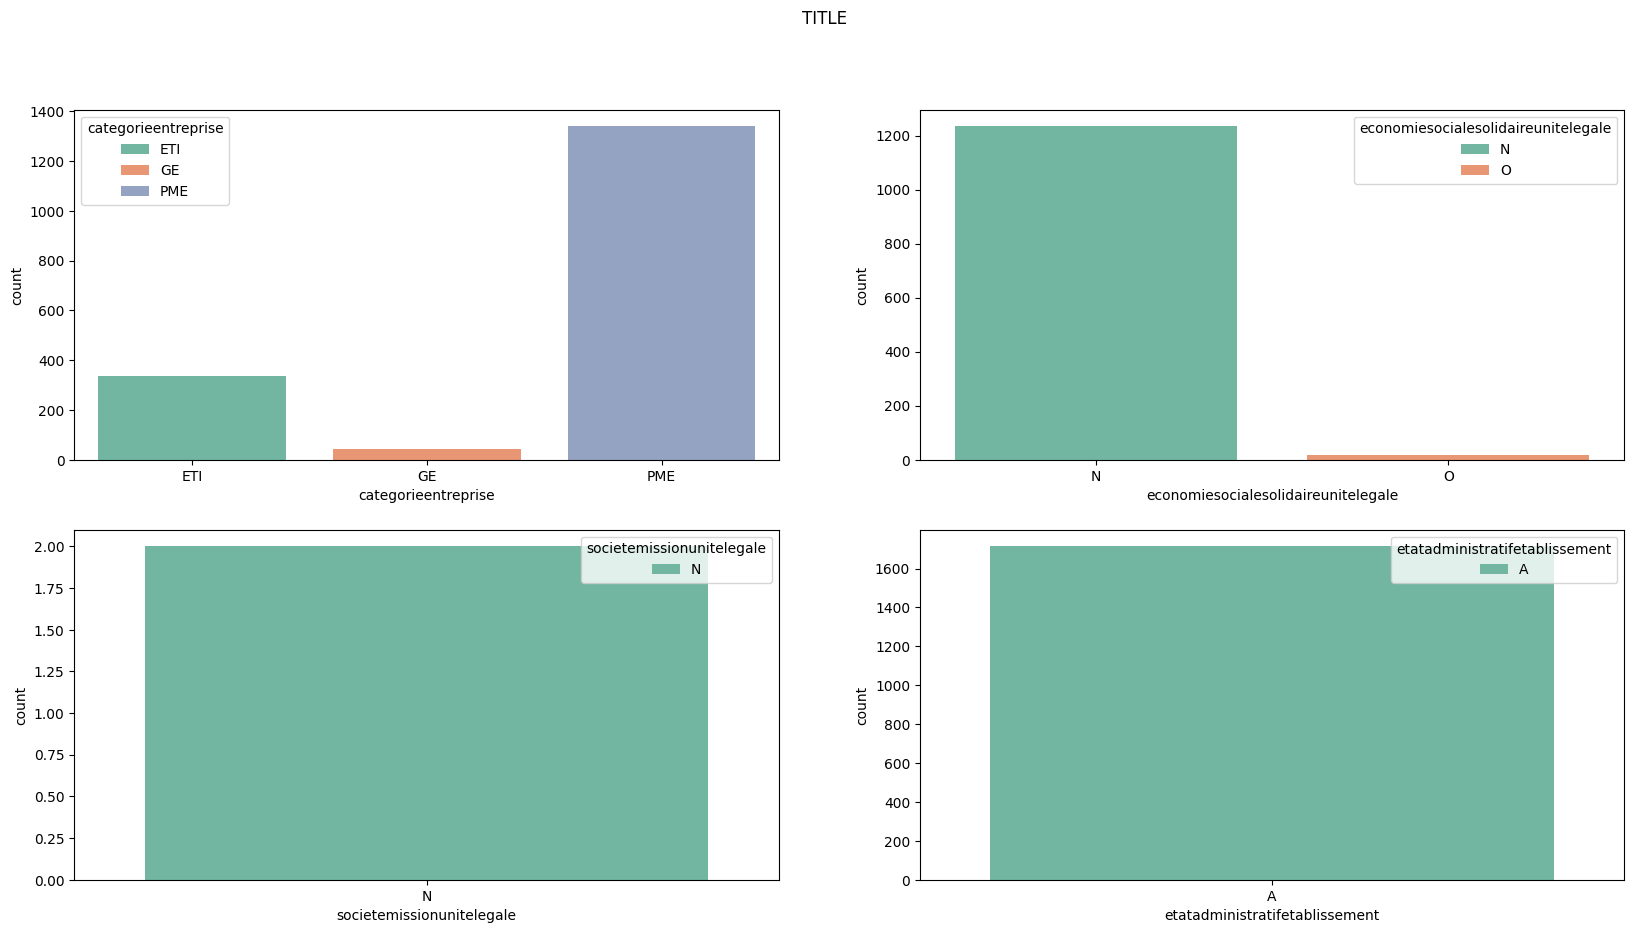

In [987]:
categorical_cols = df.select_dtypes('category').columns

fig, axes = plt.subplots(2, 2, figsize=(20, 10))
fig.suptitle('TITLE')
for i, col in enumerate(low_cardinality[:4]):
    sns.countplot(ax=axes[i // 2, i % 2], x=col, data=df, palette="Set2", hue=df[col])
plt.show()

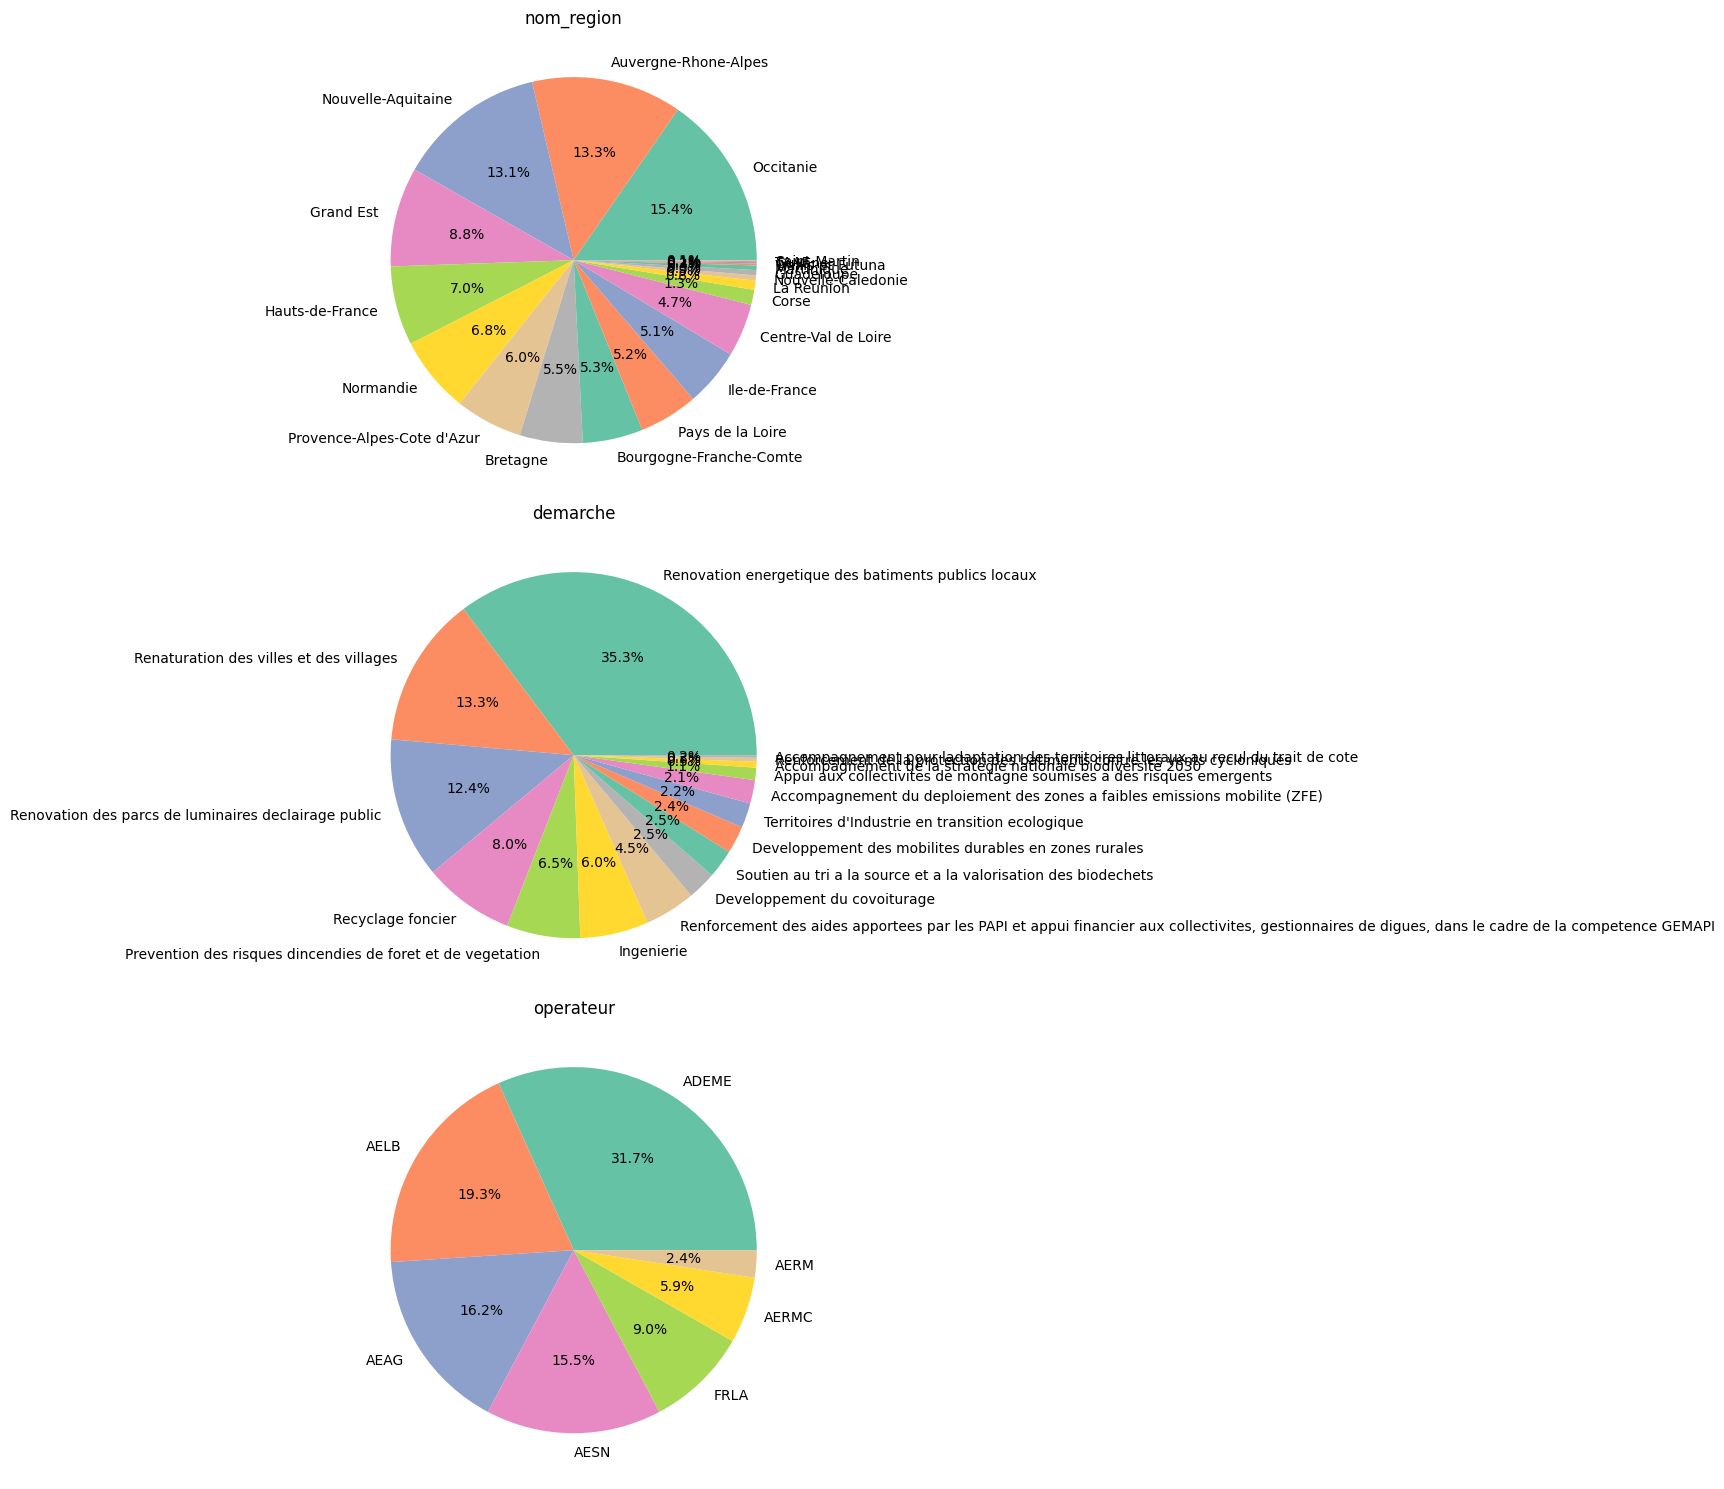

In [988]:
n_rows = len(mid_cardinality)

fig, axes = plt.subplots(n_rows, figsize=(15, 5 * n_rows))
axes = axes.flatten()

for i, col in enumerate(mid_cardinality):
    df[col].value_counts().plot(
        kind='pie',
        ax=axes[i],
        title=col,
        autopct='%1.1f%%',
        colors=palettehex
    )
    axes[i].set_ylabel('')  # Remove y-label for cleaner look

# Hide extra subplots if odd number of plots
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

We have detected only 1 numerical variable which is a subsidy size. However, the age of the company is a subject to categorical-to-numerical transition (`dateCreation`).

In [989]:
df["montant_engage"].describe()

count    1.774000e+03
mean     1.852264e+05
std      4.175044e+05
min      4.250000e+02
25%      1.811175e+04
50%      6.000000e+04
75%      1.953938e+05
max      8.921761e+06
Name: montant_engage, dtype: float64

In [990]:
df["log_montant_engage"]= np.log(df["montant_engage"])


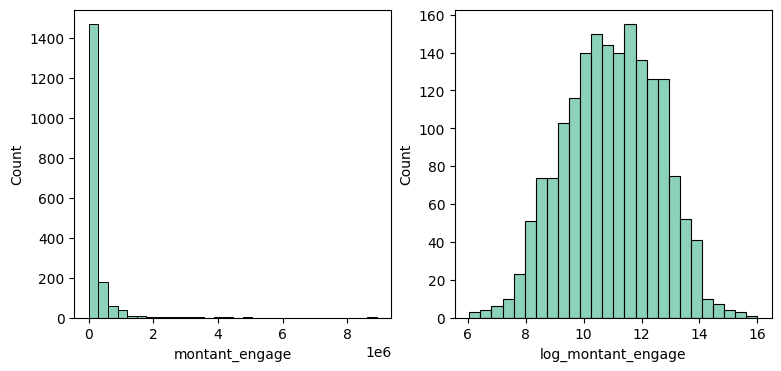

In [991]:
#Target variable distribution
fig, ax = plt.subplots(1,2,figsize=(9, 4))
sns.histplot(data=df, x="montant_engage", 
             color=palettehex[0], 
             ax=ax[0],
             bins=30)
sns.histplot(data=df, x="log_montant_engage", 
             color=palettehex[0], 
             ax=ax[1])
plt.show()

The target variable looks way more readable with the log tranformation applied.

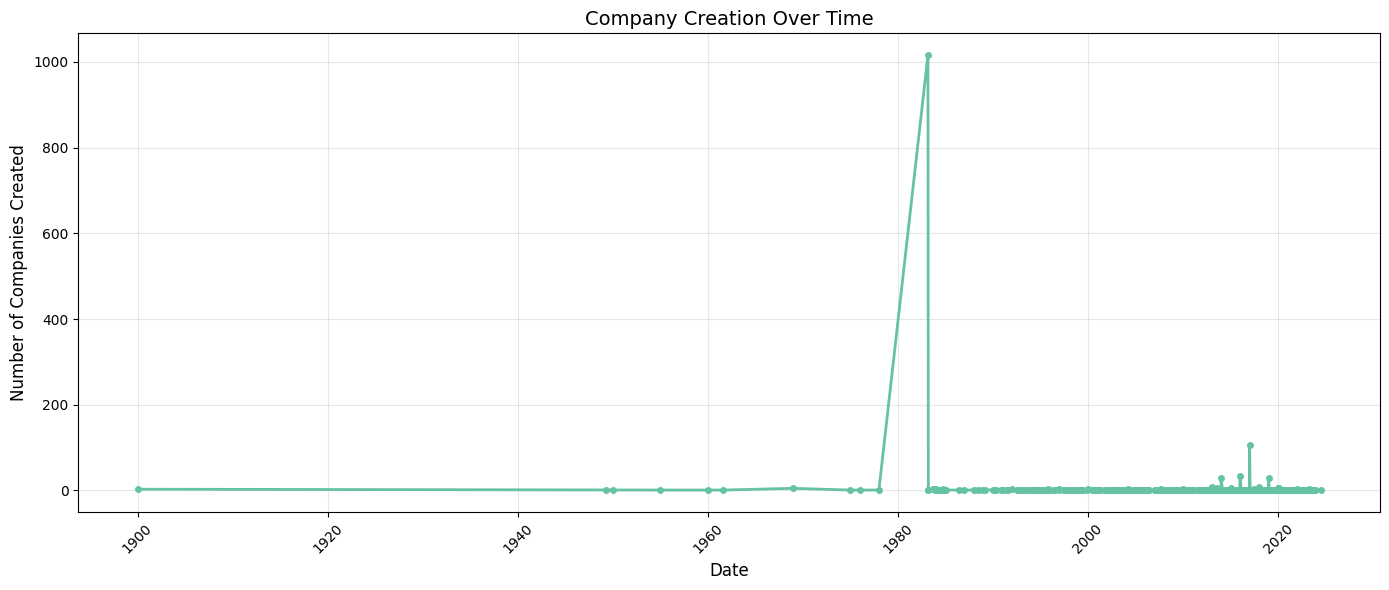

In [992]:
#Companies' age distribution
df["datecreation"] = pd.to_datetime(df["datecreation"], format='%Y-%m-%d')
df["creation_year"] = df["datecreation"].dt.year
df["year_month"] = df["datecreation"].dt.to_period('M').astype(str)

time_counts = df.groupby('datecreation').size().reset_index(name='count')
time_counts['datecreation'] = pd.to_datetime(time_counts['datecreation'])

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(time_counts['datecreation'], time_counts['count'], 
        color=palettehex[0], linewidth=2, marker='o', markersize=4)
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Number of Companies Created', fontsize=12)
ax.set_title('Company Creation Over Time', fontsize=14)
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

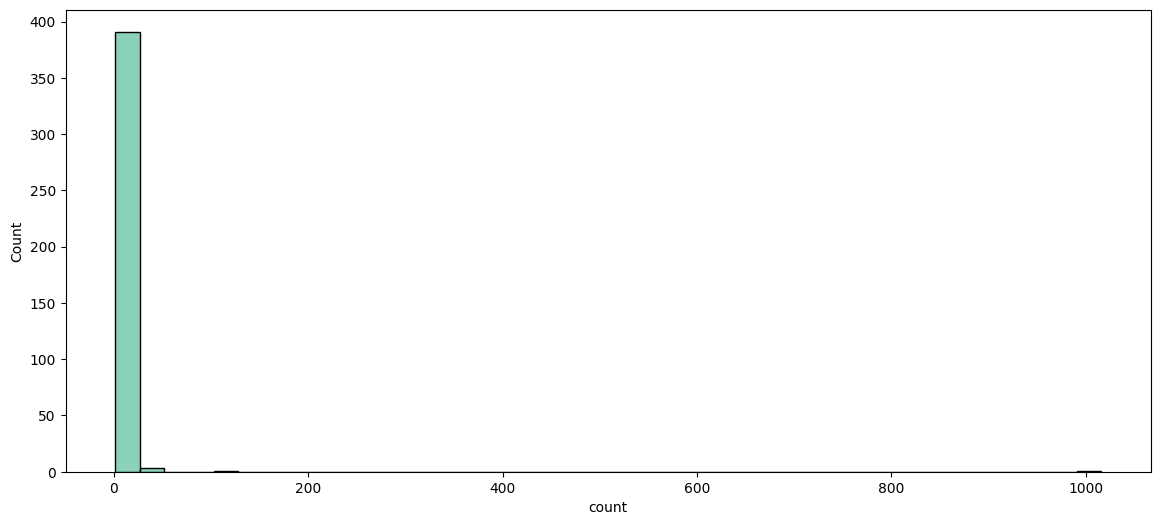

Maximum value 1016 found at index 10 corresponding to date 1983-03-01 00:00:00


In [993]:
fig, ax = plt.subplots(figsize=(14, 6))
sns.histplot(data=time_counts, x="count", 
             color=palettehex[0], 
             ax=ax)
plt.show()

for i, val in enumerate(time_counts['count']):
    max_values = time_counts['count'].max()
    if val == max_values:
        print(f"Maximum value {val} found at index {i} corresponding to date {time_counts['datecreation'][i]}")

The anomalous date was detected. 4124 firms were created in this specific date with is considered to be abnormally extreme. We'll try to find some logical explanation of this outlier, otherwise, we'll need to get rid of it since it touches a significant amount of observation, or create a special category for this variable.

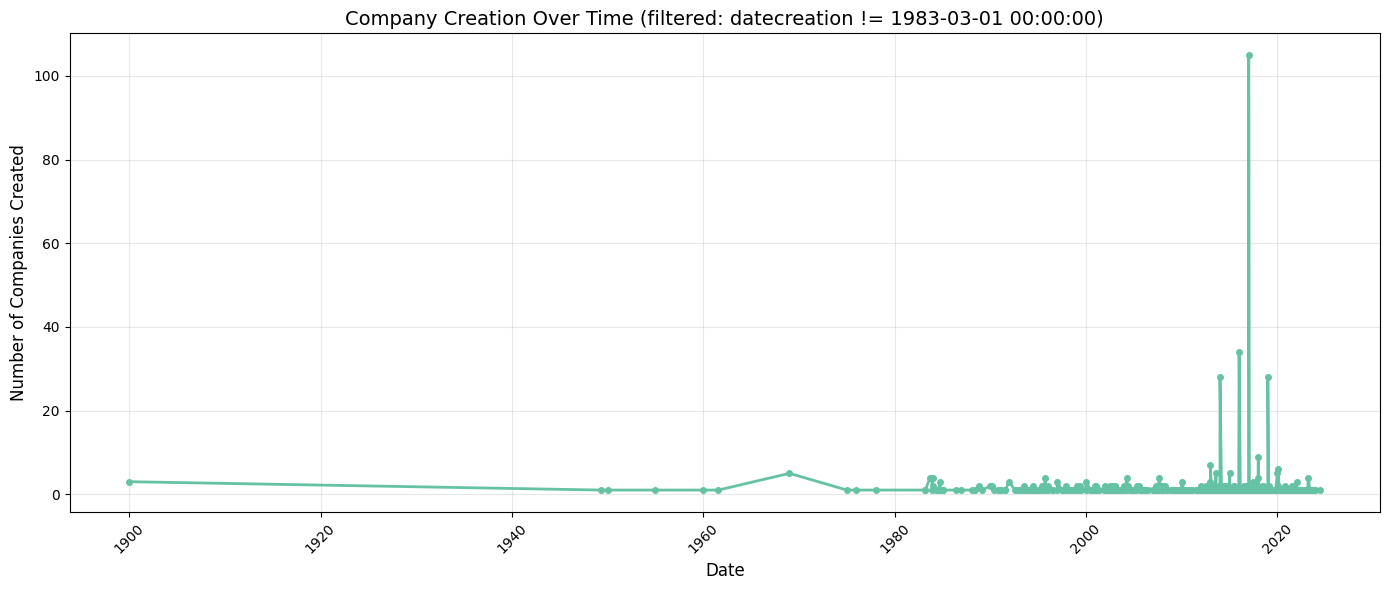

In [994]:
# Filter out extreme outliers
threshold = "1983-03-01 00:00:00"
time_counts_filtered = time_counts[time_counts['datecreation'] != threshold]

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(time_counts_filtered['datecreation'], time_counts_filtered['count'], 
        color=palettehex[0], linewidth=2, marker='o', markersize=4)
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Number of Companies Created', fontsize=12)
ax.set_title(f'Company Creation Over Time (filtered: datecreation != {threshold})', fontsize=14)
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [995]:
today = pd.Timestamp.today()
df["age_entreprise"] = (today - df["datecreation"]).dt.days / 365.25
df["age_entreprise_m"] = (today - df["datecreation"]).dt.days / 30.44

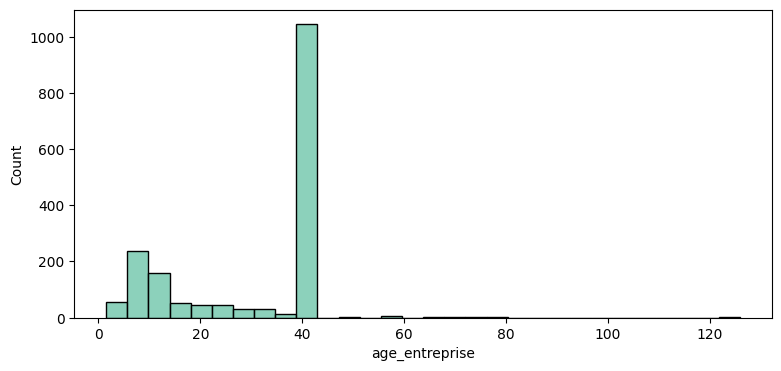

count    1731.000000
mean       31.861763
std        15.756592
min         1.514031
25%        13.010267
50%        42.850103
75%        42.850103
max       126.009582
Name: age_entreprise, dtype: float64

In [996]:
#Target variable distribution
fig, ax = plt.subplots(1,1,figsize=(9, 4))
sns.histplot(data=df, x="age_entreprise", 
             color=palettehex[0], 
             ax=ax,
             bins=30)
plt.show()

df["age_entreprise"].describe()

We will treat these extreme values as "input errors". Thus, we'll make a medium imputation and create a dummy for errors aside.

In [997]:
# Identify enterprises created at the anomalous threshold date
threshold = "1983-03-01 00:00:00"
is_extreme_age = df['datecreation'] == threshold
df['is_age_error'] = is_extreme_age.astype(int)

# Replace extreme values with NaN and impute with median
df.loc[is_extreme_age, 'age_entreprise'] = np.nan
median_age = df['age_entreprise'].median()
df['age_entreprise'] = df['age_entreprise'].fillna(median_age)

print(f"Number of age errors identified (created on {threshold}): {is_extreme_age.sum()}")
print(f"Median age used for imputation: {median_age:.2f} years")

Number of age errors identified (created on 1983-03-01 00:00:00): 1016
Median age used for imputation: 11.14 years


### NA check and treatment

In [998]:
na = df.isna().sum()/df.shape[0]*100

px.bar(na.sort_values(),
         title = "Pourcentage de valeurs manquantes par variable",
         color_discrete_sequence = palettehex[0:1],
         template='ggplot2',
         range_y = [0,100],
         width=800,
         labels={'value':'%', 'index':''},
         color=None
        ).update_traces(showlegend=False).update_xaxes(tickangle=45)

In [999]:
na = df.isna().sum()/df.shape[0]*100
na.sort_values()

nom_du_projet                           0.000000
age_entreprise                          0.000000
year_month                              0.000000
log_montant_engage                      0.000000
tranche_effectif_ord                    0.000000
is_false_info                           0.000000
trancheeffectifsunitelegale             0.000000
is_age_error                            0.000000
montant_engage                          0.000000
demarche                                1.916573
code_commune                            1.916573
nom_commune                             1.916573
raison_sociale_beneficiaire             2.254791
forme_juridique_beneficiaire            2.254791
creation_year                           2.423901
nom_region                              2.423901
datecreation                            2.423901
nom_departement                         2.423901
age_entreprise_m                        2.423901
siret                                   2.423901
siret_beneficiaire  

Before choosing candidates for the deletion, we'll take a look at the variables' meaning and try to understand if the fact that the variable is missing is something explained by its nature.

- `societemissionunitelegale`: Introduced only in 2019.
- `economiesocialesolidaireunitelegale`: Missing ≠ “unknown”; missing = “not part of the ESS perimeter and not declared”.
- `numero_operateur`: These are identifiers used only for specific legal setups
- `numero_ej`: Missing when there is no EJ separate from the legal unit, which happens in many cases.
- `age_entreprise`: imputed and a dummy added

So, these NAs are structural and we suppose that the model will loose a lot of necessary information with exclusion of these variables. We have decided to keep them selectively, and make imputation based on the meaning of each variable.

### Imputation and Clean-up

In [1000]:
print(df['societemissionunitelegale'].value_counts(dropna=False))
print(df['anneeeffectifsetablissement'].value_counts(dropna=False))
print(df['numero_ej'].value_counts(dropna=False))
print(df['economiesocialesolidaireunitelegale'].value_counts(dropna=False))
print(df['operateur'].value_counts(dropna=False))
print(df['siret'].value_counts(dropna=False))
print(df['siret_beneficiaire'].value_counts(dropna=False))

societemissionunitelegale
NaN    1772
N         2
Name: count, dtype: int64
anneeeffectifsetablissement
2023.0    1679
NaN         95
Name: count, dtype: int64
numero_ej
NaN             290
2.104329e+09      1
2.104574e+09      1
2.104374e+09      1
2.104326e+09      1
               ... 
2.104376e+09      1
2.104376e+09      1
2.104321e+09      1
2.104347e+09      1
2.104523e+09      1
Name: count, Length: 1485, dtype: int64
economiesocialesolidaireunitelegale
N      1234
NaN     522
O        18
Name: count, dtype: int64
operateur
NaN      1484
ADEME      92
AELB       56
AEAG       47
AESN       45
FRLA       26
AERMC      17
AERM        7
Name: count, dtype: int64
siret
NaN             43
2.000931e+13     6
2.175000e+13     5
2.582006e+13     5
2.497401e+13     4
                ..
2.185016e+13     1
2.000847e+13     1
2.122010e+13     1
2.482000e+13     1
2.144012e+13     1
Name: count, Length: 1580, dtype: int64
siret_beneficiaire
NaN             43
2.000931e+13     6
2.175000e+13

In [1001]:
df['numero_ej'] = df['numero_ej'].astype('object').fillna('No EJ').astype('category')
df['economiesocialesolidaireunitelegale'] = df['economiesocialesolidaireunitelegale'].astype('object').fillna('Not in ESS scope').astype('category')
df['operateur'] = df['operateur'].astype('object').fillna('Not applicable').astype('category')

After several training and testing rounds, we want to add another variable to proxy the richeness of each department. we'll add dummy for the capital of the region and the number of citizens. 

In [ ]:
# Regional capitals and population mapping for French departments
# Map commune to regional capital status
regional_capitals_france = {
    'Paris': 'Île-de-France',
    'Marseille': 'Provence-Alpes-Côte d\'Azur',
    'Lyon': 'Auvergne-Rhône-Alpes',
    'Toulouse': 'Occitanie',
    'Nice': 'Provence-Alpes-Côte d\'Azur',
    'Nantes': 'Pays de la Loire',
    'Strasbourg': 'Grand Est',
    'Montpellier': 'Occitanie',
    'Bordeaux': 'Nouvelle-Aquitaine',
    'Lille': 'Hauts-de-France',
    'Rennes': 'Bretagne',
    'Reims': 'Grand Est',
    'Le Havre': 'Normandie',
    'Saint-Étienne': 'Auvergne-Rhône-Alpes',
    'Toulon': 'Provence-Alpes-Côte d\'Azur',
    'Grenoble': 'Auvergne-Rhône-Alpes',
    'Dijon': 'Bourgogne-Franche-Comté',
    'Angers': 'Pays de la Loire',
    'Nîmes': 'Occitanie',
    'Roussillon': 'Provence-Alpes-Côte d\'Azur',
    'Toulouse': 'Occitanie',
    'Clermont-Ferrand': 'Auvergne-Rhône-Alpes',
    'Orléans': 'Centre-Val de Loire',
    'Tours': 'Centre-Val de Loire',
    'Nancy': 'Grand Est',
    'Metz': 'Grand Est',
    'Amiens': 'Hauts-de-France',
    'Rouen': 'Normandie',
    'Limoges': 'Nouvelle-Aquitaine',
    'Caen': 'Normandie',
    'Poitiers': 'Nouvelle-Aquitaine',
    'Le Mans': 'Pays de la Loire',
    'Besançon': 'Bourgogne-Franche-Comté'
}

# Create binary feature for regional capital
df['is_regional_capital'] = 0

# Clean and match commune names
for idx, row in df.iterrows():
    if pd.notna(row['nom_commune']):
        commune = str(row['nom_commune']).strip()
        if commune in regional_capitals_france:
            df.at[idx, 'is_regional_capital'] = 1

# Import department population mapping from CSV file
population_path = Path(project_root / "data" / "population.csv")
pop_df = pd.read_csv(population_path)

# Clean population data: remove commas and convert to numeric
pop_df['population'] = pop_df['population'].astype(str).str.replace(',', '').astype(float)

# Create mapping dictionary from code to population
dept_population = dict(zip(pop_df['code'].astype(str), pop_df['population']))

print(f"Population data loaded from {population_path}")
print(f"Departments in population file: {len(dept_population)}")

# Create population feature (fill missing with overall median)
df['dept_population_proxy'] = df['code_departement'].astype(str).map(dept_population)

# For unmapped departments, use overall median
median_pop = pop_df['population'].median()
df['dept_population_proxy'] = df['dept_population_proxy'].fillna(median_pop)

print(f"Regional capitals identified: {df['is_regional_capital'].sum()}")
print(f"Population proxy created (range: {df['dept_population_proxy'].min():.0f} - {df['dept_population_proxy'].max():.0f})")
print(f"Median population used for unmapped depts: {median_pop:.0f}")


In [ ]:
variable2drop=["anneeeffectifsetablissement",
               "societemissionunitelegale",
               "numero_operateur",
               #"age_entreprise",
               "datecreation",
               "codepostal",
               "nom_departement",
               "nom_region",
               "nom_commune",
               #"tranche_effectif",
               "trancheeffectifsunitelegale",
               "code_commune", 
               "numero_ej",
               "siret",
               "siret_beneficiaire",
               "raison_sociale_beneficiaire",
               "etatadministratifetablissement"]

df.drop(variable2drop,
        axis=1, 
        inplace=True)


In [1003]:
df.shape

(1774, 18)

In [1004]:
na = df.isna().sum()/df.shape[0]*100
na.sort_values()

nom_du_projet                          0.000000
age_entreprise                         0.000000
year_month                             0.000000
log_montant_engage                     0.000000
tranche_effectif_ord                   0.000000
is_false_info                          0.000000
economiesocialesolidaireunitelegale    0.000000
is_age_error                           0.000000
operateur                              0.000000
montant_engage                         0.000000
demarche                               1.916573
forme_juridique_beneficiaire           2.254791
age_entreprise_m                       2.423901
code_departement                       2.423901
creation_year                          2.423901
activiteprincipale                     2.423901
resume_du_projet                       2.649380
categorieentreprise                    2.987599
dtype: float64

To check the systematic character of the rest of the missing values we apply the contingency analysis.

### Problems with the data

- 1983 spike - solved
- Useless variables due to its NAs - solved
- Specific encoding - to do
- Textual data - to do 

### EncodingFeature Engineering

We have chosen the following variable for the encoding procedure. 

Ordinal encoding:
- tranche_effectif_ord
- categorieentreprise (PME < ETI < GE)

Nominal encoding:
- is_creation_unknown
- is_false_info (tranche_effectif)
- code_departement
- demarche
- forme_juridique_beneficiaire
- activiteprincipale
- etatadministratifetablissement
- economiesocialesolidaireunitelegal

To vectorize:
- nom_du_projet
- resume_du_projet

Target variable
- log_montant_engage
- montant_engage

Time
- year_month
- creation_year

Numerical:
- age_entreprise_filled
- age_entreprise_m

### Plan 
Use out-of-fold target encoding (K-fold with out-of-fold means) or a library that does this automatically.
Keep tranche_effectif_ord as integer (not float) if possible.
economiesocialesolidaireunitelegale → 3-level: {O, N, NA} → one-hot or ordinal-like {0,1,2}

In [1005]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1774 entries, 0 to 1773
Data columns (total 18 columns):
 #   Column                               Non-Null Count  Dtype   
---  ------                               --------------  -----   
 0   nom_du_projet                        1774 non-null   object  
 1   resume_du_projet                     1727 non-null   object  
 2   montant_engage                       1774 non-null   float64 
 3   operateur                            1774 non-null   category
 4   demarche                             1740 non-null   category
 5   code_departement                     1731 non-null   category
 6   forme_juridique_beneficiaire         1734 non-null   category
 7   activiteprincipale                   1731 non-null   category
 8   categorieentreprise                  1721 non-null   category
 9   economiesocialesolidaireunitelegale  1774 non-null   category
 10  is_false_info                        1774 non-null   int64   
 11  tranche_effectif_

In [1006]:
ordinal_columns = [
    'tranche_effectif_ord',
    "categorieentreprise"
    ]
nominal_columns = [
    #"is_creation_unknown", 
    "is_age_error",
    "operateur",
    "demarche",
    "forme_juridique_beneficiaire",
    "activiteprincipale",
    #"etatadministratifetablissement",
    "economiesocialesolidaireunitelegale",
    "is_false_info"
    ]
text_columns=[
    "nom_du_projet",
    "resume_du_projet"
]
target_columns = [
    "log_montant_engage",
    "montant_engage"
                  ] 

target_var = [
    "montant_engage"
]  
numerical_columns = [
    "age_entreprise_m",
    "age_entreprise"
]
time_columns = [
    "year_month",
    "creation_year",

]
proxy = [
    "code_departement"
]
df_encoded = df.copy()

### Ordinal / Target ordinal

In [1007]:
df[nominal_columns]
for col in nominal_columns:
    print(df[col].value_counts())

is_age_error
1    1016
0     758
Name: count, dtype: int64
operateur
Not applicable    1484
ADEME               92
AELB                56
AEAG                47
AESN                45
FRLA                26
AERMC               17
AERM                 7
Name: count, dtype: int64
demarche
Renovation energetique des batiments publics locaux                                                                                                   614
Renaturation des villes et des villages                                                                                                               232
Renovation des parcs de luminaires declairage public                                                                                                  216
Recyclage foncier                                                                                                                                     140
Prevention des risques dincendies de foret et de vegetation                                     

The rest of the nominal variables should be treated separately since their values should be either aggregated or encoded as separate variables. Before it's necessary to check the info value of each nominal non-binary variable against the target. 

- `activiteprincipale` - to choose crucial activities and to aggregate the rest of them
- `economiesocialesolidaireunitelegale` - aggregate to binary
- `forme_juridique_beneficiaire` - aggregate to ordinal (?)
- `demarche` - aggregate thematically (many binaries)
- `operateur` - aggregate to binary

In [1008]:
def bucket_forme_juridique(x):
    if pd.isna(x): 
        return "Missing"
    x = str(x).lower()

    if "commune" in x:
        return "Commune"
    if "communaute" in x or "métropole" in x or "metropole" in x:
        return "EPCI/Metropole"
    if "syndicat" in x:
        return "Syndicat"
    if "departement" in x or "région" in x or "region" in x:
        return "Departement/Region"
    if "association" in x:
        return "Association"
    if "sas" in x or "sarl" in x or "sa" in x or "soci" in x:
        return "Entreprise"
    if "etablissement public" in x or "epci" in x:
        return "Etablissement_public"

    return "Autre_statut"

In [1009]:
df_agg = df.copy()
df_agg["forme_juridique_grp"] = df_agg["forme_juridique_beneficiaire"].map(bucket_forme_juridique)

In [1010]:
df_agg["forme_juridique_grp"].value_counts()

forme_juridique_grp
Commune                 1230
Syndicat                 152
EPCI/Metropole           117
Entreprise                98
Departement/Region        60
Missing                   40
Etablissement_public      31
Autre_statut              25
Association               21
Name: count, dtype: int64

In [1011]:
def bucket_naf2(code):
    """Coarse NAF group buckets by first two digits."""
    if pd.isna(code):
        return "Missing"
    c = str(code)
    pref2 = c[:2]

    # Agriculture / extraction
    if pref2 in {"01", "02", "03"}:
        return "Agriculture"
    if pref2 in {"05", "06", "07", "08", "09"}:
        return "Mining"

    # Manufacturing (grouped by similar chains)
    if pref2 in {"10", "11", "12"}:
        return "Food_Beverage"
    if pref2 in {"13", "14", "15"}:
        return "Textile"
    if pref2 in {"16", "17", "18"}:
        return "Wood_Paper_Print"
    if pref2 in {"20", "21"}:
        return "Chemicals_Pharma"
    if pref2 in {"22", "23"}:
        return "Plastics_Mineral"
    if pref2 in {"24", "25", "26", "27", "28"}:
        return "Metals_Machinery"
    if pref2 in {"29", "30", "33"}:
        return "Transport_Equip"

    # Utilities & construction
    if pref2 == "35":
        return "Energy"
    if pref2 in {"36", "37", "38", "39"}:
        return "Water_Waste"
    if pref2 in {"41", "42", "43"}:
        return "Construction"

    # Trade, transport, hospitality
    if pref2 in {"45", "46", "47"}:
        return "Trade"
    if pref2 in {"49", "50", "51", "52", "53"}:
        return "Transport_Logistics"
    if pref2 in {"55", "56"}:
        return "Hospitality"

    # Information & communication
    if pref2 in {"58", "59", "60"}:
        return "Media"
    if pref2 in {"61", "62", "63"}:
        return "ICT"

    # Finance & real estate
    if pref2 in {"64", "65", "66"}:
        return "Finance"
    if pref2 == "68":
        return "Real_estate"

    # Professional / technical / admin services
    if pref2 in {"69", "70", "71", "72", "73", "74", "75"}:
        return "Prof_Tech_Sci"
    if pref2 in {"77", "78", "79", "80", "81", "82"}:
        return "Admin_Support"

    # Public, education, health, social
    if pref2 == "84":
        return "Public_admin"
    if pref2 == "85":
        return "Education"
    if pref2 in {"86", "87", "88"}:
        return "Health_Social"

    # Arts, recreation, other services
    if pref2 in {"90", "91", "92", "93"}:
        return "Arts_Recreation"
    if pref2 in {"94", "95", "96"}:
        return "Other_services"

    # Fallback
    return "Other_naf"

In [1012]:
df_agg["naf_grp"] = df_agg["activiteprincipale"].map(bucket_naf2)
df_agg["naf_grp"].value_counts()

naf_grp
Public_admin           1568
Missing                  43
Real_estate              33
Water_Waste              24
Construction             22
Prof_Tech_Sci            13
Other_services           12
Health_Social            10
Food_Beverage             8
Energy                    6
Education                 4
Textile                   4
Plastics_Mineral          4
Hospitality               4
Wood_Paper_Print          3
Transport_Logistics       3
Trade                     2
Admin_Support             2
Chemicals_Pharma          2
Metals_Machinery          2
Other_naf                 2
Transport_Equip           1
Finance                   1
Arts_Recreation           1
Name: count, dtype: int64

In [1013]:
df_agg["ess_bin"] = (df_agg["economiesocialesolidaireunitelegale"] == "O").astype(int)
df_agg["ess_bin"].value_counts()

ess_bin
0    1756
1      18
Name: count, dtype: int64

In [1014]:
def bucket_demarche(x):
    if pd.isna(x):
        return "Missing"

    if "Renovation energetique" in x or "luminaires" in x:
        return "Energie"
    if "Renaturation" in x or "Recyclage foncier" in x or "biodiversite" in x:
        return "Biodiversite_sols"
    if "mobilites" in x or "covoiturage" in x or "ZFE" in x:
        return "Mobilites"
    if "incendies" in x or "montagne" in x or "littoraux" in x or "cycloniques" in x:
        return "Risques_climatiques"
    if "PAPI" in x or "GEMAPI" in x or "Plan eau" in x:
        return "Eau"
    if "biodechets" in x or "tri a la source" in x:
        return "Dechets_economie_circulaire"
    if "Territoires d'Industrie" in x:
        return "Developpement_economique"
    if "Ingenierie" in x:
        return "Ingenierie"

    return "Autre"

In [1015]:
df_agg["demarche"] = df_agg["demarche"].map(bucket_demarche)
df_agg["demarche"].value_counts()

demarche
Energie                        830
Biodiversite_sols              381
Risques_climatiques            142
Mobilites                      122
Ingenierie                     105
Eau                             78
Dechets_economie_circulaire     44
Developpement_economique        38
Missing                         34
Name: count, dtype: int64

In [1016]:
def bucket_operateur(x):
    if pd.isna(x) or x == "Not applicable":
        return "None"

    if x == "ADEME":
        return "Environmental_agency"

    if x in {"AELB", "AESN", "AEAG", "AERMC", "AERM"}:
        return "Water_agency"

    if x == "FRLA":
        return "Financial_fund"

    return "Other"

df_agg["operateur_type"] = df_agg["operateur"].map(bucket_operateur)

# бинарные признаки
df_agg["has_operator"] = (df_agg["operateur_type"] != "None").astype(int)
df_agg["is_water_agency"] = (df_agg["operateur_type"] == "Water_agency").astype(int)
df_agg["is_ademe"] = (df_agg["operateur_type"] == "Environmental_agency").astype(int)
df_agg["is_financial_operator"] = (df_agg["operateur_type"] == "Financial_fund").astype(int)

In [1017]:
df_agg.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1774 entries, 0 to 1773
Data columns (total 26 columns):
 #   Column                               Non-Null Count  Dtype   
---  ------                               --------------  -----   
 0   nom_du_projet                        1774 non-null   object  
 1   resume_du_projet                     1727 non-null   object  
 2   montant_engage                       1774 non-null   float64 
 3   operateur                            1774 non-null   category
 4   demarche                             1774 non-null   object  
 5   code_departement                     1731 non-null   category
 6   forme_juridique_beneficiaire         1734 non-null   category
 7   activiteprincipale                   1731 non-null   category
 8   categorieentreprise                  1721 non-null   category
 9   economiesocialesolidaireunitelegale  1774 non-null   category
 10  is_false_info                        1774 non-null   int64   
 11  tranche_effectif_

In [1018]:
# Ordinal encoding for categorieentreprise (PME < ETI < GE), 0 for missing
categorieentreprise_map = {
    'PME': 1,
    'ETI': 2,
    'GE': 3
}
df_agg['categorieentreprise'] = (
    df_agg['categorieentreprise']
    .astype('object')                # drop categorical dtype constraints
    .fillna('Missing')
    .map(categorieentreprise_map)
    .fillna(0)
)
print("Categorieentreprise encoding complete (0 = missing):")
print(df_agg['categorieentreprise'].value_counts().sort_index())

Categorieentreprise encoding complete (0 = missing):
categorieentreprise
0.0      53
1.0    1340
2.0     338
3.0      43
Name: count, dtype: int64


### Assembling and encoding the variable of interest

In [ ]:
ordinal_columns = ['tranche_effectif_ord', 'categorieentreprise']

numerical_columns = [
    #"age_entreprise_m",
    "age_entreprise",
    "dept_population_proxy",  # Department population proxy for richness
    #"creation_year",
    #"year_month"
]

binary_columns = [
    "is_age_error",
    "is_false_info",
    "ess_bin",
    "has_operator",
    "is_water_agency",
    "is_ademe",
    "is_financial_operator",
    "is_regional_capital",  # Binary indicator for regional capitals
    #"is_overseas"
]

nominal_compact = [
    "forme_juridique_grp",
    "naf_grp",
    "operateur_type",
    "demarche"
]

text_columns=[
    "nom_du_projet",
    "resume_du_projet"
]

target_var = [
    "montant_engage"
    # "log_montant_engage"
]


In [1020]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

# Collapse rare categories to reduce redundant dummies

def collapse_tail(series, top_n=8, min_frac=0.01, other_label="Other"):
    freq = series.value_counts(normalize=True)
    keep = set(freq.head(top_n).index) | set(freq[freq >= min_frac].index)
    return series.where(series.isin(keep), other_label)

# Apply tail collapse on selected grouped categoricals
for col in ["naf_grp", "forme_juridique_grp", "demarche"]:
    df_agg[col] = collapse_tail(df_agg[col], top_n=8, min_frac=0.01, other_label=f"Other_{col}")

df_encoded = df_agg.copy()

encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore",
    drop="first"
)

nominal_ohe = encoder.fit_transform(df_encoded[nominal_compact])
nominal_feature_names = encoder.get_feature_names_out(nominal_compact)

nominal_ohe_df = pd.DataFrame(
    nominal_ohe,
    columns=nominal_feature_names,
    index=df_encoded.index
)


In [1021]:
df_final = pd.concat(
    [
        df_encoded[ordinal_columns],
        df_encoded[numerical_columns],
        df_encoded[binary_columns],
        df_encoded[target_var],
        df_encoded[text_columns],
        nominal_ohe_df
    ],
    axis=1
)

print("Final shape:", df_final.shape)
print("Number of features:", df_final.shape[1])
df_final.head()

Final shape: (1774, 40)
Number of features: 40


,tranche_effectif_ord,categorieentreprise,age_entreprise,is_age_error,is_false_info,ess_bin,has_operator,is_water_agency,is_ademe,is_financial_operator,...,operateur_type_None,operateur_type_Water_agency,demarche_Dechets_economie_circulaire,demarche_Developpement_economique,demarche_Eau,demarche_Energie,demarche_Ingenierie,demarche_Missing,demarche_Mobilites,demarche_Risques_climatiques
0,5,1.0,11.143053,1,0,0,0,0,0,0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,5,1.0,11.143053,1,0,0,0,0,0,0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,4,1.0,11.143053,1,0,0,0,0,0,0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,6,1.0,12.514716,0,0,0,0,0,0,0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,10,2.0,9.010267,0,0,0,0,0,0,0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


### Text vectorization with TF-IDF

We decided to convert `Nom du projet`, `Resume du projet` to vector dimention to extract token based information from these long texts. Another way of doing this conversion is labeling (manual or automated).

Because subsidies are typically determined by:

- type of project (rénovation énergétique, éclairage public…)
- object category (école, mairie, batiment, salle, parc…)
- operations (réhabilitation, remplacement, création…)
- context (commune, ville, territoire)

TF–IDF captures these terms perfectly.

In [1022]:
df_final.columns

Index(['tranche_effectif_ord', 'categorieentreprise', 'age_entreprise',
       'is_age_error', 'is_false_info', 'ess_bin', 'has_operator',
       'is_water_agency', 'is_ademe', 'is_financial_operator',
       'montant_engage', 'nom_du_projet', 'resume_du_projet',
       'forme_juridique_grp_Autre_statut', 'forme_juridique_grp_Commune',
       'forme_juridique_grp_Departement/Region',
       'forme_juridique_grp_EPCI/Metropole', 'forme_juridique_grp_Entreprise',
       'forme_juridique_grp_Etablissement_public',
       'forme_juridique_grp_Missing', 'forme_juridique_grp_Syndicat',
       'naf_grp_Health_Social', 'naf_grp_Missing', 'naf_grp_Other_naf_grp',
       'naf_grp_Other_services', 'naf_grp_Prof_Tech_Sci',
       'naf_grp_Public_admin', 'naf_grp_Real_estate', 'naf_grp_Water_Waste',
       'operateur_type_Financial_fund', 'operateur_type_None',
       'operateur_type_Water_agency', 'demarche_Dechets_economie_circulaire',
       'demarche_Developpement_economique', 'demarche_Eau', '

In [1023]:
# text data statistics
df_final["len_chars"] = df_final["resume_du_projet"].fillna("").str.len()
df_final["len_words"] = df_final["resume_du_projet"].fillna("").str.split().str.len()

# Basic stats
print(df_final["len_chars"].describe())
print(df_final["len_words"].describe())


count    1774.000000
mean      617.221533
std       407.764558
min         0.000000
25%       331.000000
50%       598.500000
75%       881.000000
max      4684.000000
Name: len_chars, dtype: float64
count    1774.000000
mean       95.450958
std        64.062862
min         0.000000
25%        51.000000
50%        93.000000
75%       134.000000
max       685.000000
Name: len_words, dtype: float64


In [1024]:
french_stopwords = [
        'le', 'de', 'un', 'et', 'à', 'être', 'en', 'que', 'pour', 'dans',
        'ce', 'il', 'qui', 'ne', 'sur', 'se', 'pas', 'plus', 'pouvoir', 'par',
        'je', 'avec', 'tout', 'nous', 'ou', 'aller', 'vouloir', 'dire', 'elle',
        'aussi', 'bien', 'moi', 'autre', 'celui', 'même', 'lui', 'avoir', 'nos',
        'vous', 'mon', 'son', 'ton', 'ta', 'ma', 'sa', 'ça', 'cet', 'cette',
        'ces', 'les', 'la', 'les', 'du', 'des', 'au', 'aux', 'sont', 'est',
        'était', 'sera', 'seraient', 'peut', 'peuvent', 'faire', 'dois', 'doit',
        'dois', 'au', 'un', 'une', 'des', 'enfin', 'ete', 'ainsi', 'mise', 'dun',
        'afin', 'tres', 'moins', 'sous', 'etre', 'etre', 'été', 'être', 'depuis', 
        'entre', 'ainsi', 'cela', 'celà', 'ont', 'car', 'lorsque', 'lorsqu',
    ]

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words=french_stopwords,
    ngram_range=(1, 2),
    max_features=15,
    min_df=5,
    max_df=0.85,
    sublinear_tf=True,
    norm="l2"
)

# Fit and transform
resume_tfidf = tfidf.fit_transform(df_final['resume_du_projet'].fillna(''))

# Convert to dataframe
resume_vec = pd.DataFrame(resume_tfidf.toarray(), 
                              columns=[f'resume_tfidf_{i}' for i in range(resume_tfidf.shape[1])],
                              index=df_final.index)

In [1025]:
resume_vec.head()

,resume_tfidf_0,resume_tfidf_1,resume_tfidf_2,resume_tfidf_3,resume_tfidf_4,resume_tfidf_5,resume_tfidf_6,resume_tfidf_7,resume_tfidf_8,resume_tfidf_9,resume_tfidf_10,resume_tfidf_11,resume_tfidf_12,resume_tfidf_13,resume_tfidf_14
0,0.542558,0.0,0.000000,0.000000,0.000000,0.000000,0.640523,0.000000,0.226528,0.000000,0.000000,0.000000,0.0,0.494012,0.0
1,0.000000,0.0,0.307622,0.240782,0.000000,0.268766,0.000000,0.308351,0.208269,0.552921,0.575308,0.000000,0.0,0.000000,0.0
2,0.000000,0.0,0.000000,0.000000,0.398033,0.517643,0.395645,0.350757,0.236912,0.000000,0.386516,0.297538,0.0,0.000000,0.0
3,0.816568,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.577249,0.000000,0.000000,0.000000,0.0,0.000000,0.0
4,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0


In [1026]:
resume_tfidf = tfidf.fit_transform(df_final['resume_du_projet'].fillna(''))
resume_tfidf.nnz / (resume_tfidf.shape[0] * resume_tfidf.shape[1])

0.19425028184892898

In [1027]:
vocab = tfidf.get_feature_names_out()
idfs = tfidf.idf_
sorted_words = sorted(zip(idfs, vocab))[:50]
sorted_words[:100]


[(np.float64(1.8628167183922968), 'projet'),
 (np.float64(2.1536189181803214), 'commune'),
 (np.float64(2.3395182963221597), 'renovation'),
 (np.float64(2.39933679153307), 'travaux'),
 (np.float64(2.4039134585604818), 'energetique'),
 (np.float64(2.6351169268517918), 'batiment'),
 (np.float64(2.7514559189359415), 'cadre'),
 (np.float64(2.7579705999571353), 'place'),
 (np.float64(2.9208740708939884), 'public'),
 (np.float64(3.039137991387723), 'remplacement'),
 (np.float64(3.0699096500544765), 'batiments'),
 (np.float64(3.097060639120427), 'ville'),
 (np.float64(3.1016583483690567), 'territoire'),
 (np.float64(3.1109176737818536), 'isolation'),
 (np.float64(3.12969756843345), 'dune')]

### Final dataset assembly 

Numeric block shape before filtering: (1774, 40)
After variance filter: (1774, 40), dropped 0 cols
After correlation filter: (1774, 36), dropped 4 cols
Dropped high-corr columns: ['len_words', 'operateur_type_Financial_fund', 'operateur_type_None', 'operateur_type_Water_agency']


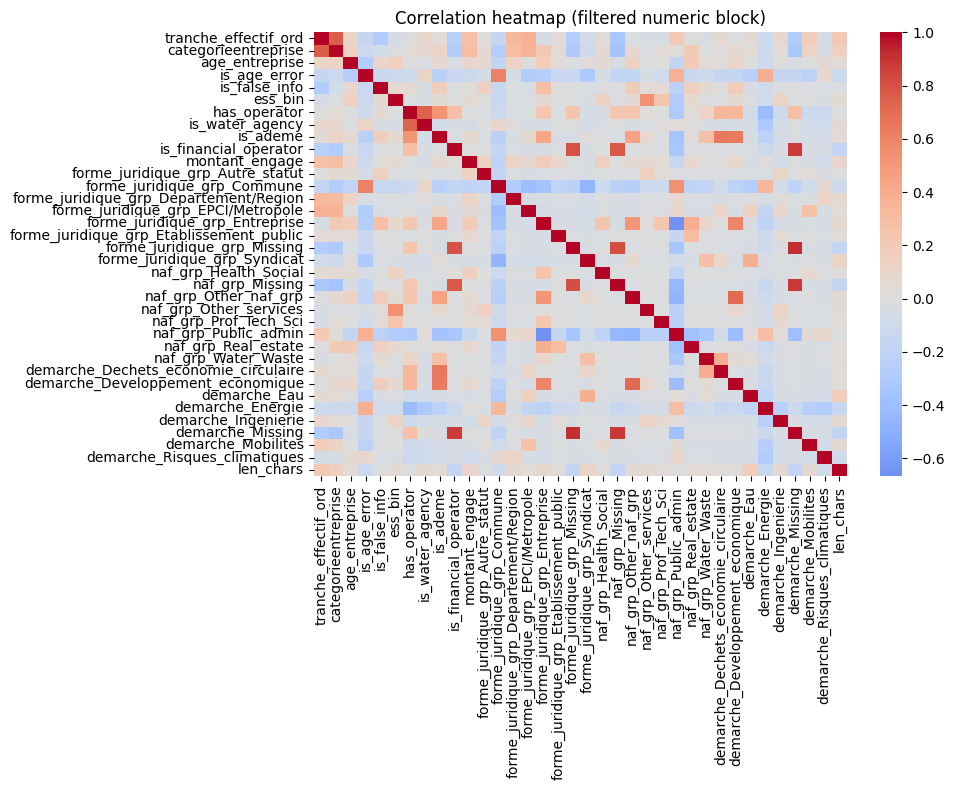

df_final final shape after filters: (1774, 38)


In [ ]:
# Remove near-zero-variance and highly correlated numeric features (incl. TF-IDF) and visualize correlations
import numpy as np
from sklearn.feature_selection import VarianceThreshold
import matplotlib.pyplot as plt
import seaborn as sns

numeric_block = df_final.select_dtypes(include=["float64", "float32", "int64", "Int32", "Int64"])
print(f"Numeric block shape before filtering: {numeric_block.shape}")

# Near-zero variance filter
vt = VarianceThreshold(threshold=1e-5)
vt.fit(numeric_block)
keep_mask = vt.get_support()
kept_cols = numeric_block.columns[keep_mask]

dropped_low_var = sorted(set(numeric_block.columns) - set(kept_cols))
numeric_filtered = numeric_block[kept_cols]
print(f"After variance filter: {numeric_filtered.shape}, dropped {len(dropped_low_var)} cols")
if dropped_low_var:
    print("Dropped low-variance columns:", dropped_low_var)

# Correlation filter (absolute > 0.95)
corr = numeric_filtered.corr()
abs_corr = corr.abs()
upper = abs_corr.where(np.triu(np.ones(abs_corr.shape), k=1).astype(bool))
to_drop_corr = [col for col in upper.columns if any(upper[col] > 0.95)]

numeric_final = numeric_filtered.drop(columns=to_drop_corr, errors="ignore")
print(f"After correlation filter: {numeric_final.shape}, dropped {len(to_drop_corr)} cols")
if to_drop_corr:
    print("Dropped high-corr columns:", sorted(to_drop_corr))

# Plot correlation heatmap (limited to remaining numeric columns)
plt.figure(figsize=(10, 8))
sns.heatmap(numeric_final.corr(), cmap="coolwarm", center=0, square=False)
plt.title("Correlation heatmap (filtered numeric block)")
plt.tight_layout()
plt.show()

# Replace numeric block in df_final
#remaining_non_numeric = df_final.drop(columns=numeric_block.columns, errors="ignore")
#df_final = pd.concat([numeric_final, remaining_non_numeric], axis=1)
#print(f"df_final final shape after filters: {df_final.shape}")


In [1029]:
# Drop raw text and length helper columns, then add TF-IDF features
cols_to_drop = ['resume_du_projet', 'nom_du_projet', 'len_chars', 'len_words']
df_final = df_final.drop(columns=cols_to_drop, errors='ignore')

df_final = pd.concat([df_final, resume_vec], axis=1)

print(df_final.shape)
df_final.head()

(1774, 50)


,tranche_effectif_ord,categorieentreprise,age_entreprise,is_age_error,is_false_info,ess_bin,has_operator,is_water_agency,is_ademe,is_financial_operator,...,resume_tfidf_5,resume_tfidf_6,resume_tfidf_7,resume_tfidf_8,resume_tfidf_9,resume_tfidf_10,resume_tfidf_11,resume_tfidf_12,resume_tfidf_13,resume_tfidf_14
0,5,1.0,11.143053,1,0,0,0,0,0,0,...,0.000000,0.640523,0.000000,0.226528,0.000000,0.000000,0.000000,0.0,0.494012,0.0
1,5,1.0,11.143053,1,0,0,0,0,0,0,...,0.268766,0.000000,0.308351,0.208269,0.552921,0.575308,0.000000,0.0,0.000000,0.0
2,4,1.0,11.143053,1,0,0,0,0,0,0,...,0.517643,0.395645,0.350757,0.236912,0.000000,0.386516,0.297538,0.0,0.000000,0.0
3,6,1.0,12.514716,0,0,0,0,0,0,0,...,0.000000,0.000000,0.000000,0.577249,0.000000,0.000000,0.000000,0.0,0.000000,0.0
4,10,2.0,9.010267,0,0,0,0,0,0,0,...,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0


In [1030]:
print(f"Initial shape: {df_final.shape}")
float_cols = df_final.select_dtypes(include=['float64', 'float32']).columns
print(f"\nConverting {len(float_cols)} float columns to int...")
print(f"Float columns: {float_cols.tolist()}")

for col in float_cols:
    df_final[col] = (df_final[col]).round().astype('Int32')

print("\nFinal dtypes:")
print(df_final.dtypes)
print(f"\nFinal shape: {df_final.shape}")

Initial shape: (1774, 50)

Converting 42 float columns to int...
Float columns: ['categorieentreprise', 'age_entreprise', 'montant_engage', 'forme_juridique_grp_Autre_statut', 'forme_juridique_grp_Commune', 'forme_juridique_grp_Departement/Region', 'forme_juridique_grp_EPCI/Metropole', 'forme_juridique_grp_Entreprise', 'forme_juridique_grp_Etablissement_public', 'forme_juridique_grp_Missing', 'forme_juridique_grp_Syndicat', 'naf_grp_Health_Social', 'naf_grp_Missing', 'naf_grp_Other_naf_grp', 'naf_grp_Other_services', 'naf_grp_Prof_Tech_Sci', 'naf_grp_Public_admin', 'naf_grp_Real_estate', 'naf_grp_Water_Waste', 'demarche_Dechets_economie_circulaire', 'demarche_Developpement_economique', 'demarche_Eau', 'demarche_Energie', 'demarche_Ingenierie', 'demarche_Missing', 'demarche_Mobilites', 'demarche_Risques_climatiques', 'resume_tfidf_0', 'resume_tfidf_1', 'resume_tfidf_2', 'resume_tfidf_3', 'resume_tfidf_4', 'resume_tfidf_5', 'resume_tfidf_6', 'resume_tfidf_7', 'resume_tfidf_8', 'resume_tf

In [1031]:
# df_final.to_csv(project_root / "data" / "df_final.csv", index=False)
df_final.to_csv(project_root / "data" / "df_test.csv", index=False)